In [1]:
import matplotlib
import matplotlib.pyplot as plt

print(matplotlib.__version__)
print(matplotlib.__file__)

3.11.2
/home/pratay-karali/Desktop/flowstate/.venv/lib/python3.12/site-packages/matplotlib/__init__.py


/home/pratay-karali/Desktop/flowstate/.venv/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


In [2]:
%run reproducibility.py

True
False
Baseline: tensor([5.6245, 5.0030, 4.4007, 3.8229, 3.2920])
Variant : tensor([5.6245, 5.4356, 5.2473, 5.0592, 4.8711])


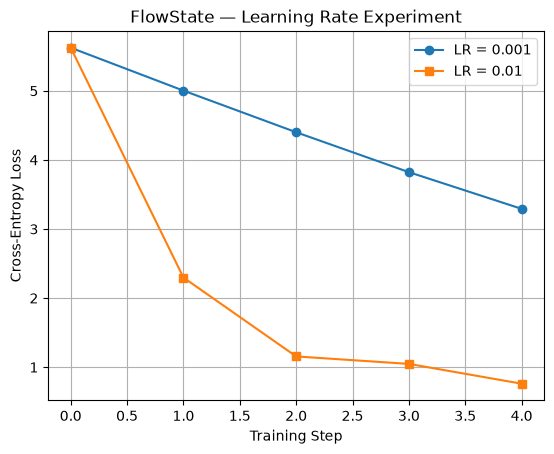

In [3]:
import matplotlib.pyplot as plt

baseline = train_once(42, steps=5, lr=1e-3)
variant = train_once(42, steps=5, lr=1e-2)

steps = range(5)

plt.plot(steps, baseline, marker="o", label="LR = 0.001")
plt.plot(steps, variant, marker="s", label="LR = 0.01")

plt.xlabel("Training Step")
plt.ylabel("Cross-Entropy Loss")
plt.title("FlowState — Learning Rate Experiment")
plt.legend()
plt.grid(True)
plt.show()

In [4]:
import numpy as np

seeds = [7, 21, 42, 99, 123]
learning_rates = [0.001, 0.01]

results = {}

for lr in learning_rates:
    all_losses = []

    for seed in seeds:
        losses = train_once(
            seed=seed,
            steps=5,
            lr=lr
        )

        all_losses.append(losses)

    results[lr] = np.array(all_losses)

    print(f"LR = {lr}")
    print("Final losses:", results[lr][:, -1])
    print("Mean final loss:", results[lr][:, -1].mean())
    print("Std final loss:", results[lr][:, -1].std(ddof=1))
    print()

LR = 0.001
Final losses: [3.3715985 3.290614  3.2919815 3.1936293 3.22303  ]
Mean final loss: 3.2741706
Std final loss: 0.06924965

LR = 0.01
Final losses: [0.7976504  0.6181067  0.7607832  0.55378085 0.8005994 ]
Mean final loss: 0.7061841
Std final loss: 0.11318764



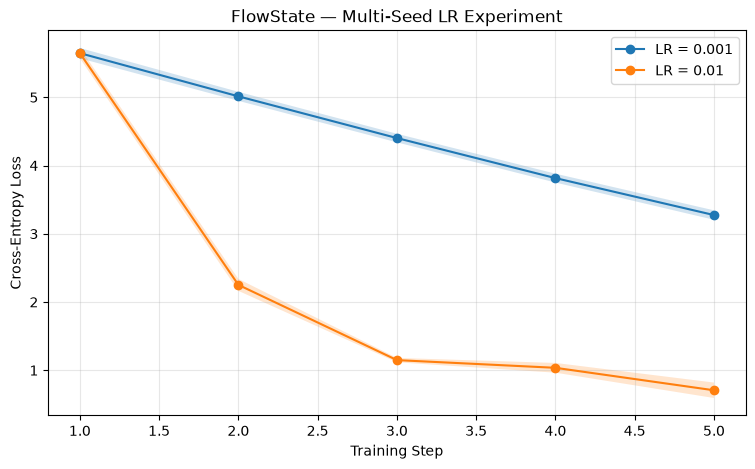

In [5]:
plt.figure(figsize=(9, 5))

for lr in learning_rates:
    runs = results[lr]

    mean = runs.mean(axis=0)
    std = runs.std(axis=0, ddof=1)

    steps = np.arange(1, len(mean) + 1)

    plt.plot(
        steps,
        mean,
        marker="o",
        label=f"LR = {lr}"
    )

    plt.fill_between(
        steps,
        mean - std,
        mean + std,
        alpha=0.2
    )

plt.xlabel("Training Step")
plt.ylabel("Cross-Entropy Loss")
plt.title("FlowState — Multi-Seed LR Experiment")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [6]:
steps_long = 50
results_50 = {}

for lr in learning_rates:
    runs = []

    for seed in seeds:
        losses = train_once(
            seed=seed,
            steps=steps_long,
            lr=lr
        )
        runs.append(losses)

    results_50[lr] = np.array(runs)

    final = results_50[lr][:, -1]

    print(f"\nLearning rate: {lr}")
    print(f"Mean final loss: {final.mean():.4f}")
    print(f"Std final loss: {final.std(ddof=1):.4f}")
    print(f"All losses finite: {np.isfinite(results_50[lr]).all()}")


Learning rate: 0.001
Mean final loss: 0.0193
Std final loss: 0.0007
All losses finite: True

Learning rate: 0.01
Mean final loss: 0.0002
Std final loss: 0.0000
All losses finite: True


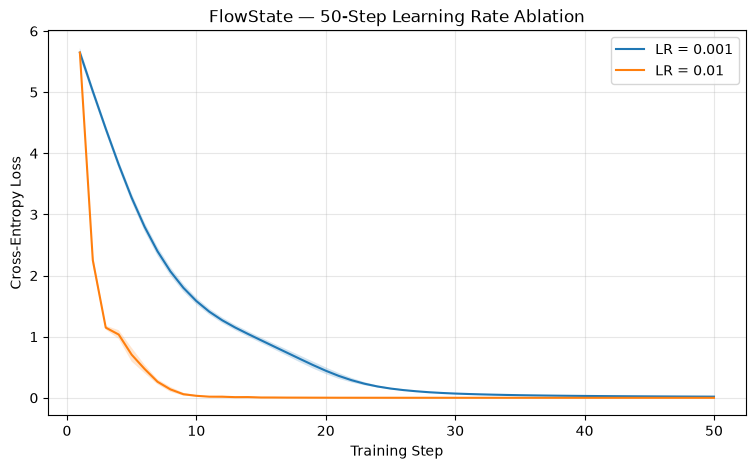

In [7]:
plt.figure(figsize=(9, 5))

for lr, runs in results_50.items():
    mean = runs.mean(axis=0)
    std = runs.std(axis=0, ddof=1)

    x = np.arange(1, len(mean) + 1)

    plt.plot(x, mean, label=f"LR = {lr}")
    plt.fill_between(
        x, mean - std, mean + std,
        alpha=0.2
    )

plt.title("FlowState — 50-Step Learning Rate Ablation")
plt.xlabel("Training Step")
plt.ylabel("Cross-Entropy Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

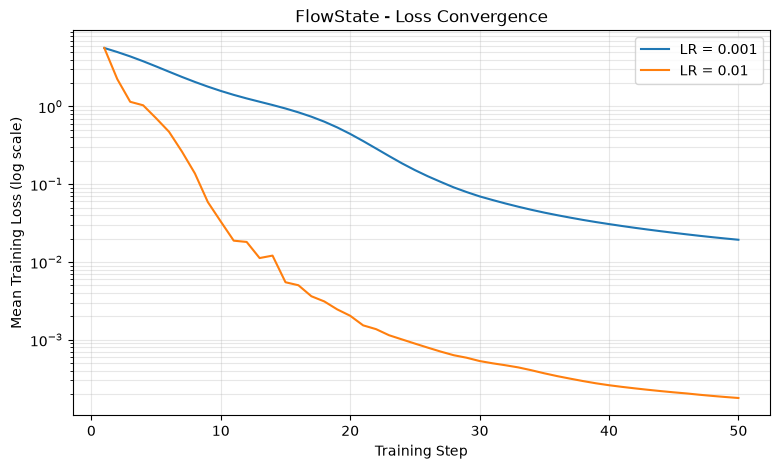

LR 0.001: 0.01932461
LR 0.01: 0.00017834


In [8]:
plt.figure(figsize=(9, 5))

for lr, runs in results_50.items():
    mean = runs.mean(axis=0)

    plt.plot(
        range(1, len(mean) + 1),
        mean,
        label=f"LR = {lr}"
    )

plt.yscale("log")
plt.xlabel("Training Step")
plt.ylabel("Mean Training Loss (log scale)")
plt.title("FlowState - Loss Convergence")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

for lr, runs in results_50.items():
    print(f"LR {lr}: {runs[:, -1].mean():.8f}")

In [9]:
train_texts = [
    "A dragon guards a tiny library.",
    "A dragon reads a dusty book.",
    "A wizard guards an old library.",
    "A knight reads a tiny book."
]

val_texts = [
    "A wizard reads a dusty book.",
    "A knight guards an old library."
]
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

def sequence_loss(model, sentence):
    tokens = torch.tensor(
        [list(sentence.encode("utf-8"))],
        dtype=torch.long
    )

    logits = model(tokens)

    return F.cross_entropy(
        logits[:, :-1, :].reshape(-1, logits.shape[-1]),
        tokens[:, 1:].reshape(-1)
    )

In [10]:
def train_with_validation(seed, lr, steps=50):
    torch.manual_seed(seed)

    model = create_model(seed)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=lr
    )

    train_history = []
    val_history = []
    checkpoints = []

    for step in range(steps):
        model.train()

        # Cycle through training sentences
        sentence = train_texts[step % len(train_texts)]

        optimizer.zero_grad(set_to_none=True)

        loss = sequence_loss(model, sentence)

        loss.backward()
        optimizer.step()

        # Evaluate every 5 steps
        if (step + 1) % 5 == 0:
            model.eval()

            with torch.no_grad():
                train_loss = np.mean([
                    sequence_loss(model, text).item()
                    for text in train_texts
                ])

                val_loss = np.mean([
                    sequence_loss(model, text).item()
                    for text in val_texts
                ])

            checkpoints.append(step + 1)
            train_history.append(train_loss)
            val_history.append(val_loss)

    return checkpoints, train_history, val_history

LR=0.001 | Train=0.2295 | Validation=0.4079
LR=0.01 | Train=0.2645 | Validation=0.5465


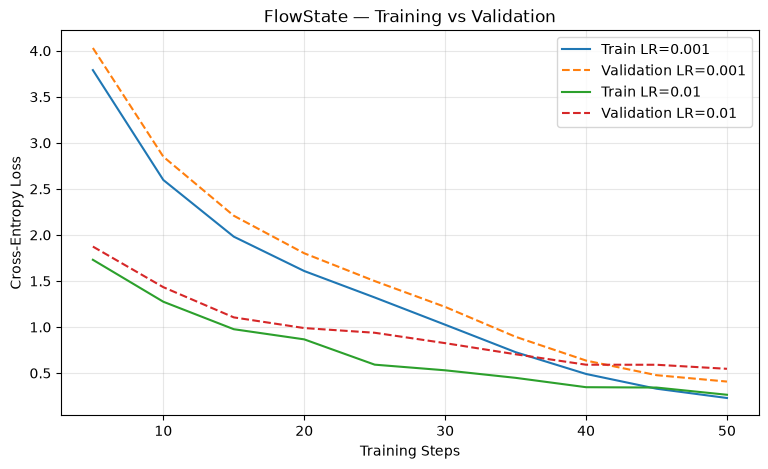

In [11]:
plt.figure(figsize=(9, 5))

for lr in [0.001, 0.01]:
    x, train_losses, val_losses = train_with_validation(
        seed=42,
        lr=lr,
        steps=50
    )

    plt.plot(
        x, train_losses,
        label=f"Train LR={lr}"
    )

    plt.plot(
        x, val_losses,
        linestyle="--",
        label=f"Validation LR={lr}"
    )

    print(
        f"LR={lr} | "
        f"Train={train_losses[-1]:.4f} | "
        f"Validation={val_losses[-1]:.4f}"
    )

plt.xlabel("Training Steps")
plt.ylabel("Cross-Entropy Loss")
plt.title("FlowState — Training vs Validation")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [12]:
seeds = [7, 21, 42, 99, 123]
learning_rates = [0.001, 0.01]

validation_results = {}

for lr in learning_rates:
    final_losses = []

    for seed in seeds:
        steps, train_hist, val_hist = train_with_validation(
            seed=seed,
            lr=lr,
            steps=50
        )

        final_losses.append(val_hist[-1])

    validation_results[lr] = np.array(final_losses)

    print(f"\nLR = {lr}")
    print("Validation losses:", final_losses)
    print("Mean:", np.mean(final_losses))
    print("Std:", np.std(final_losses, ddof=1))


LR = 0.001
Validation losses: [np.float64(0.45572155714035034), np.float64(0.40966905653476715), np.float64(0.40788546204566956), np.float64(0.4267624318599701), np.float64(0.3412720412015915)]
Mean: 0.4082621097564697
Std: 0.04208459252398345

LR = 0.01
Validation losses: [np.float64(0.6229593753814697), np.float64(0.5266672968864441), np.float64(0.5465103685855865), np.float64(0.6608665287494659), np.float64(0.6004694998264313)]
Mean: 0.5914946138858795
Std: 0.055020918113121285


In [13]:
low_lr = validation_results[0.001]
high_lr = validation_results[0.01]

difference = high_lr - low_lr

for seed, diff in zip(seeds, difference):
    print(
        f"Seed {seed}: "
        f"validation loss difference = {diff:+.4f}"
    )

print("\nMean paired difference:", difference.mean())
print("Seeds favoring LR 0.001:", np.sum(difference > 0))

Seed 7: validation loss difference = +0.1672
Seed 21: validation loss difference = +0.1170
Seed 42: validation loss difference = +0.1386
Seed 99: validation loss difference = +0.2341
Seed 123: validation loss difference = +0.2592

Mean paired difference: 0.18323250412940978
Seeds favoring LR 0.001: 5


In [14]:
import json
from pathlib import Path

output_dir = Path("results")
output_dir.mkdir(exist_ok=True)

report = {
    "experiment": "learning_rate_validation",
    "steps": 50,
    "seeds": seeds,
    "train_texts": train_texts,
    "val_texts": val_texts,
    "results": {}
}

for lr, losses in validation_results.items():
    report["results"][str(lr)] = {
        "validation_losses": losses.tolist(),
        "mean": float(losses.mean()),
        "std": float(losses.std(ddof=1))
    }

path = output_dir / "lr_validation_50steps.json"

with open(path, "w") as f:
    json.dump(report, f, indent=4)

print("Saved:", path.resolve())

Saved: /home/pratay-karali/Desktop/flowstate/chap-2/results/lr_validation_50steps.json


In [15]:
import json
from pathlib import Path

path = Path("results/lr_validation_50steps.json")

with open(path, "r") as f:
    saved = json.load(f)

print("Experiment:", saved["experiment"])
print("Seeds:", saved["seeds"])

for lr, result in saved["results"].items():
    print(f"LR {lr}: mean={result['mean']:.4f}")

assert saved["steps"] == 50
assert len(saved["seeds"]) == 5

print("✅ Experiment record verified!")

Experiment: learning_rate_validation
Seeds: [7, 21, 42, 99, 123]
LR 0.001: mean=0.4083
LR 0.01: mean=0.5915
✅ Experiment record verified!
